# 03. Кластерный анализ клиентов (K-Means)

**Цель:** Использовать метод машинного обучения (K-Means) для выделения скрытых групп клиентов на основе их покупательского поведения (Recency, Frequency, Monetary). Это позволяет маркетингу создавать персонализированные предложения для каждого кластера, не тратя бюджет на всех подряд.

In [1]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore') # Убираем лишние предупреждения


con = duckdb.connect()
con.execute("CREATE OR REPLACE VIEW orders AS SELECT * FROM read_csv_auto('../data/raw/olist_orders_dataset.csv')")
con.execute("CREATE OR REPLACE VIEW customers AS SELECT * FROM read_csv_auto('../data/raw/olist_customers_dataset.csv')")
con.execute("CREATE OR REPLACE VIEW payments AS SELECT * FROM read_csv_auto('../data/raw/olist_order_payments_dataset.csv')")

# Считаем RFM-метрики для каждого клиента
rfm_query = """
WITH customer_orders AS (
    SELECT 
        c.customer_unique_id,
        MAX(DATE(o.order_purchase_timestamp)) AS last_purchase,
        COUNT(DISTINCT o.order_id) AS frequency,
        SUM(p.payment_value) AS monetary
    FROM orders o
    JOIN customers c ON o.customer_id = c.customer_id
    JOIN payments p ON o.order_id = p.order_id
    WHERE o.order_status = 'delivered' AND p.payment_value > 0
    GROUP BY 1
)
SELECT 
    customer_unique_id,
    DATE_DIFF('day', last_purchase, (SELECT MAX(DATE(order_purchase_timestamp)) FROM orders)) AS recency,
    frequency,
    monetary
FROM customer_orders
"""
rfm_df = con.execute(rfm_query).df()
print("Данные RFM готовы, количество клиентов:", rfm_df.shape[0])

Данные RFM готовы, количество клиентов: 93357


### Масштабирование данных и поиск оптимального количества кластеров
Так как признаки имеют разный масштаб (дни, штуки, деньги), мы используем `StandardScaler`. Затем построим «метод локтя» (Elbow Method), чтобы найти оптимальное число кластеров.

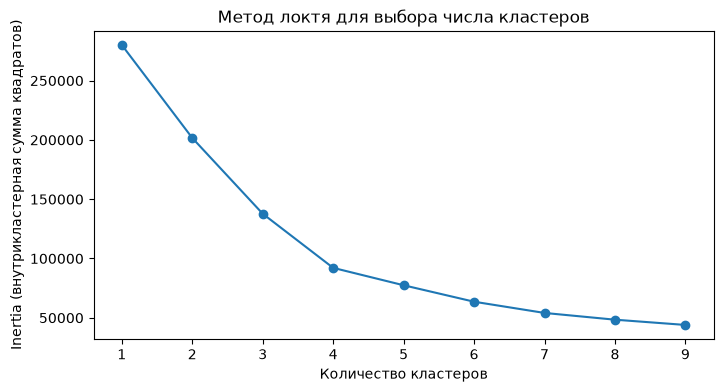

In [2]:
# Масштабируем данные
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_df[['recency', 'frequency', 'monetary']])

# Метод локтя
inertia = []
for k in range(1, 10):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(rfm_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(range(1, 10), inertia, marker='o')
plt.title('Метод локтя для выбора числа кластеров')
plt.xlabel('Количество кластеров')
plt.ylabel('Inertia (внутрикластерная сумма квадратов)')
plt.show()

In [3]:
# Запускаем K-Means на 4 кластера (визуально по графику локтя обычно выбирают 3 или 4)
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm_df['cluster'] = kmeans.fit_predict(rfm_scaled)

# Смотрим средние значения по кластерам
cluster_summary = rfm_df.groupby('cluster').agg({
    'recency': 'mean',
    'frequency': 'mean',
    'monetary': 'mean',
    'customer_unique_id': 'count'
}).rename(columns={'customer_unique_id': 'count'}).reset_index()

# Округляем для красоты
cluster_summary['recency'] = cluster_summary['recency'].round(0)
cluster_summary['frequency'] = cluster_summary['frequency'].round(1)
cluster_summary['monetary'] = cluster_summary['monetary'].round(0)

display(cluster_summary)

,cluster,recency,frequency,monetary,count
0,0,436.0,1.0,134.0,37448
1,1,269.0,2.1,290.0,2772
2,2,288.0,1.0,1161.0,2417
3,3,177.0,1.0,134.0,50720


###  Интерпретация кластеров (Бизнес-портреты)

На основе средних значений Recency, Frequency и Monetary я выделила 4 скрытых сегмента клиентов:

*   **Кластер 3 (Новички / Разовые покупатели, 50 720 чел.):** Купили недавно (в среднем 177 дней назад), но совершили только 1 покупку. **Стратегия:** Это самая большая группа. Наша задача — конвертировать их во вторую покупку через Welcome-цепочки и промокоды.
*   **Кластер 0 (Спящие / Потерянные, 37 448 чел.):** Не покупали очень давно (в среднем 436 дней). **Стратегия:** Реактивационные кампании (email/SMS со скидкой). Если не вернутся — исключить из рассылок, чтобы не тратить бюджет.
*   **Кластер 2 (Крупные чеки, 2 417 чел.):** Купили один раз, но на очень крупную сумму (средний чек 1161). **Стратегия:** Это B2B-клиенты или покупатели дорогой техники. Им нужен персональный менеджер и эксклюзивные условия, а не массовые скидки.
*   **Кластер 1 (Лояльные / Возвращающиеся, 2 772 чел.):** Покупают чаще других (в среднем 2.1 раза). **Стратегия:** Это ядро базы. Программа лояльности (кэшбэк, ранний доступ к распродажам), чтобы они не ушли к конкурентам.

**Вывод:** Большая часть базы (Кластеры 0 и 3) — это разовые покупатели. Главный вызов для бизнеса — удержать их и перевести в Кластер 1.